In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [5]:
import os
import pandas as pd

# Point directly to the 'data' folder found in MyDrive
DATA_DIR = "/content/drive/MyDrive/data/"

try:
    train = pd.read_csv(DATA_DIR + "train.csv", parse_dates=["Date"], low_memory=False)
    store = pd.read_csv(DATA_DIR + "store.csv")

    df = train.merge(store, on="Store", how="left")
    df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

    print("Success!")
    print("Dataframe shape:", df.shape)
    print("Date range:", df["Date"].min(), "to", df["Date"].max())
    display(df.head())
except FileNotFoundError as e:
    print(f"Could not find the files at {DATA_DIR}.")
    print("Please verify if train.csv and store.csv are inside your 'data' folder.")
    print("Actual contents of 'data' folder:")
    try:
        print(os.listdir(DATA_DIR))
    except Exception as list_err:
        print("Error listing folder:", list_err)

Success!
Dataframe shape: (1017209, 18)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,2,2013-01-01,0,0,0,0,a,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,1,3,2013-01-02,5530,668,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
2,1,4,2013-01-03,4327,578,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
3,1,5,2013-01-04,4486,619,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
4,1,6,2013-01-05,4997,635,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN


In [6]:
df.info()
df.isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[ns]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  object        
 10  Assortment                 1017209 non-null  object        
 11  CompetitionDistance        1014567 no

,0
Store,0
DayOfWeek,0
Date,0
Sales,0
Customers,0
Open,0
Promo,0
StateHoliday,0
SchoolHoliday,0
StoreType,0


In [8]:
#cell 1:handle missing values
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(df["CompetitionDistance"].median())
df["CompetitionOpenSinceMonth"] = df["CompetitionOpenSinceMonth"].fillna(0)
df["CompetitionOpenSinceYear"] = df["CompetitionOpenSinceYear"].fillna(0)
df["Promo2SinceWeek"] = df["Promo2SinceWeek"].fillna(0)
df["Promo2SinceYear"] = df["Promo2SinceYear"].fillna(0)
df["PromoInterval"] = df["PromoInterval"].fillna("None")

df.isna().sum().sum()   # should print 0

np.int64(0)

In [9]:
#cell 2:closed days
print((df["Open"] == 0).sum(), "closed days")
print(df[df["Open"] == 0]["Sales"].sum())   # should be 0

df_open = df[df["Open"] == 1].copy()

172817 closed days
0


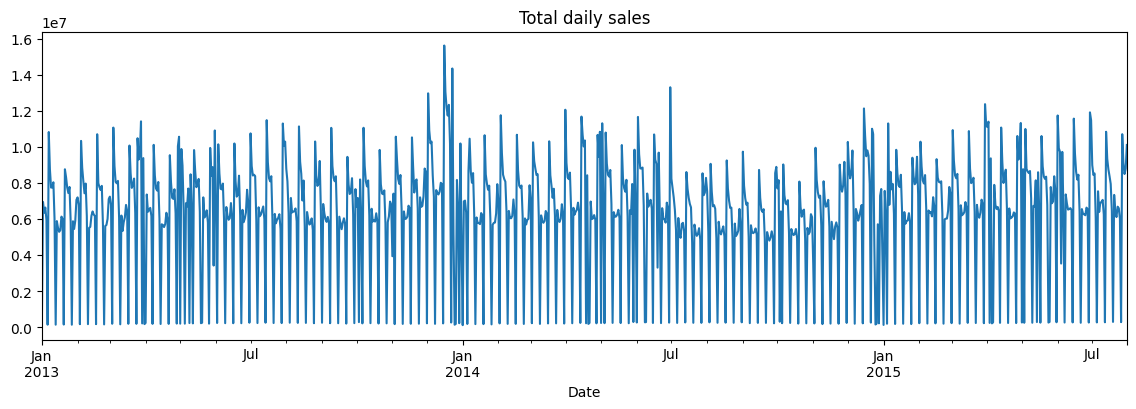

In [10]:
#cell 3:total sales overtime
import matplotlib.pyplot as plt

daily = df_open.groupby("Date")["Sales"].sum()
daily.plot(figsize=(14, 4), title="Total daily sales")
plt.show()

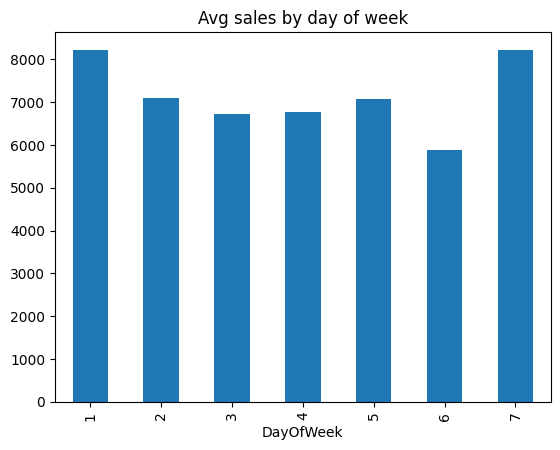

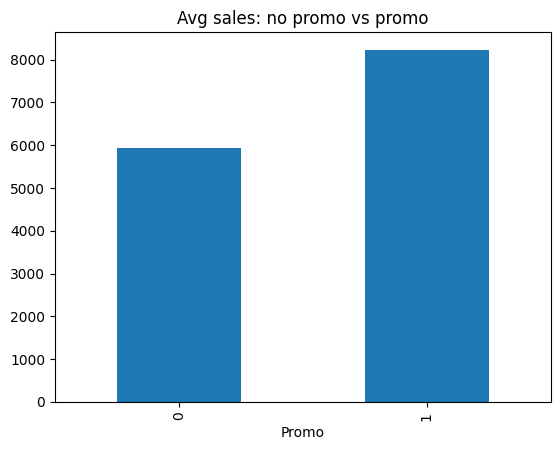

In [11]:
#cell 4:weekly patterns and promo effects
df_open.groupby("DayOfWeek")["Sales"].mean().plot(kind="bar", title="Avg sales by day of week")
plt.show()

df_open.groupby("Promo")["Sales"].mean().plot(kind="bar", title="Avg sales: no promo vs promo")
plt.show()


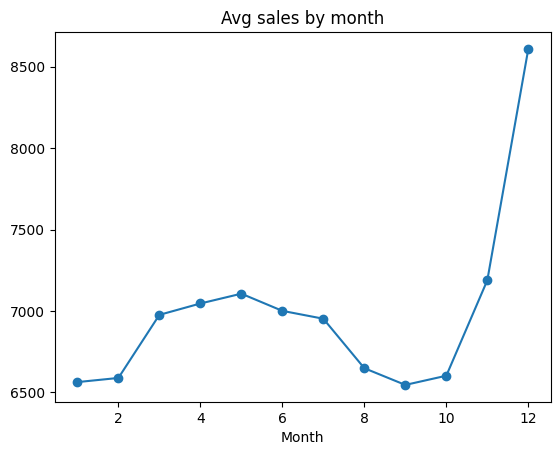

StateHoliday
0    6953.515034
a    8487.471182
b    9887.889655
c    9743.746479
Name: Sales, dtype: float64
SchoolHoliday
0    6896.782411
1    7200.181650
Name: Sales, dtype: float64


In [12]:
#cell5: monthly seasonality and holidays
df_open["Month"] = df_open["Date"].dt.month
df_open.groupby("Month")["Sales"].mean().plot(kind="line", marker="o", title="Avg sales by month")
plt.show()

print(df_open.groupby("StateHoliday")["Sales"].mean())
print(df_open.groupby("SchoolHoliday")["Sales"].mean())

In [13]:
#feature engineering
# 1. Date features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

# 2. Lag features (sales 7, 14, 28 days earlier for the same store)
for lag in [7, 14, 28]:
    tmp = df[["Store", "Date", "Sales"]].copy()
    tmp["Date"] = tmp["Date"] + pd.Timedelta(days=lag)
    tmp = tmp.rename(columns={"Sales": f"lag_{lag}"})
    df = df.merge(tmp, on=["Store", "Date"], how="left")

# 3. Rolling averages (shifted by 7 so they only use past data)
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)
g = df.groupby("Store")["Sales"]
df["roll_mean_7"] = g.transform(lambda s: s.shift(7).rolling(7).mean())
df["roll_mean_28"] = g.transform(lambda s: s.shift(7).rolling(28).mean())

# 4. Encode text columns as numbers
df["StateHoliday"] = df["StateHoliday"].astype(str)
for col in ["StateHoliday", "StoreType", "Assortment", "PromoInterval"]:
    df[col] = df[col].astype("category").cat.codes

# 5. Keep open days, drop rows without lag history
model_df = df[df["Open"] == 1].dropna(subset=["lag_7", "lag_14", "lag_28", "roll_mean_7", "roll_mean_28"])
print(model_df.shape)

(809319, 27)


In [14]:
split_date = "2015-06-19"   # last ~6 weeks as validation
train_df = model_df[model_df["Date"] < split_date]
valid_df = model_df[model_df["Date"] >= split_date]
print(train_df.shape, valid_df.shape)

(767923, 27) (41396, 27)


In [16]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

features = [
    "Store", "DayOfWeek", "Promo", "StateHoliday", "SchoolHoliday",
    "StoreType", "Assortment", "CompetitionDistance",
    "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear",
    "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval",
    "Year", "Month", "Day", "WeekOfYear",
    "lag_7", "lag_14", "lag_28", "roll_mean_7", "roll_mean_28",
]

X_train, y_train = train_df[features], train_df["Sales"]
X_valid, y_valid = valid_df[features], valid_df["Sales"]

results = {}

def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mask = y_true > 0   # avoid dividing by zero in MAPE
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    results[name] = {"MAE": round(mae, 1), "RMSE": round(rmse, 1), "MAPE %": round(mape, 2)}
    print(name, results[name])

In [17]:
# Baseline 1: same as last week
evaluate("Last week (lag_7)", y_valid, valid_df["lag_7"])

# Baseline 2: 28-day moving average
evaluate("Moving avg (28d)", y_valid, valid_df["roll_mean_28"])

Last week (lag_7) {'MAE': 2178.0, 'RMSE': np.float64(2809.1), 'MAPE %': np.float64(31.82)}
Moving avg (28d) {'MAE': 1489.4, 'RMSE': np.float64(2106.2), 'MAPE %': np.float64(20.44)}


In [18]:
#linear regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate("Linear Regression", y_valid, lr.predict(X_valid))

Linear Regression {'MAE': 824.1, 'RMSE': np.float64(1139.3), 'MAPE %': np.float64(12.82)}


In [19]:
#light GBM
import lightgbm as lgb

lgbm = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
lgbm.fit(X_train, y_train)
evaluate("LightGBM", y_valid, lgbm.predict(X_valid))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.073052 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1985
[LightGBM] [Info] Number of data points in the train set: 767923, number of used features: 23
[LightGBM] [Info] Start training from score 6982.792574
LightGBM {'MAE': 620.1, 'RMSE': np.float64(900.4), 'MAPE %': np.float64(9.45)}


In [20]:
#comparison
pd.DataFrame(results).T.sort_values("MAE")

,MAE,RMSE,MAPE %
LightGBM,620.1,900.4,9.45
Linear Regression,824.1,1139.3,12.82
Moving avg (28d),1489.4,2106.2,20.44
Last week (lag_7),2178.0,2809.1,31.82


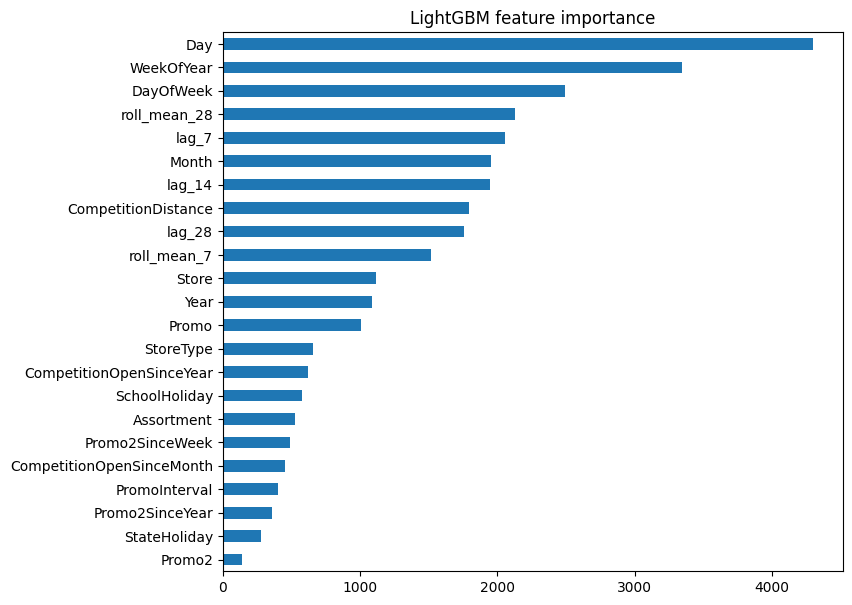

In [21]:
#feature importance
imp = pd.Series(lgbm.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(8, 7), title="LightGBM feature importance")
plt.show()

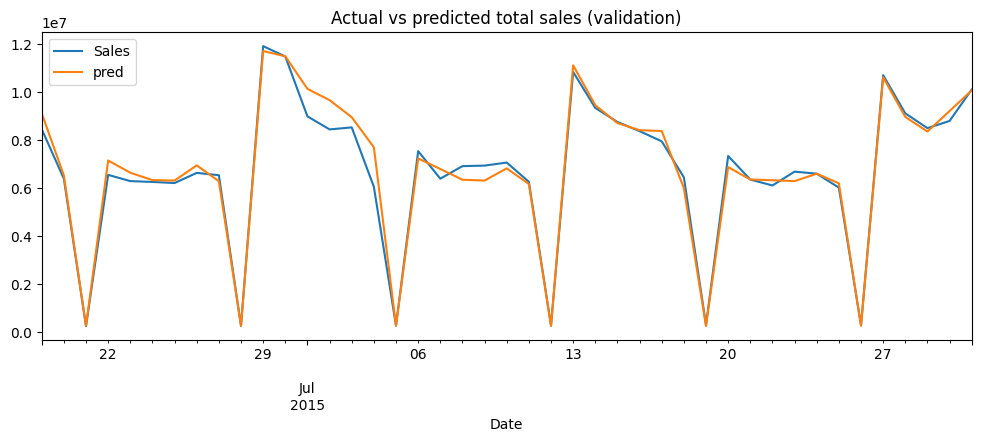

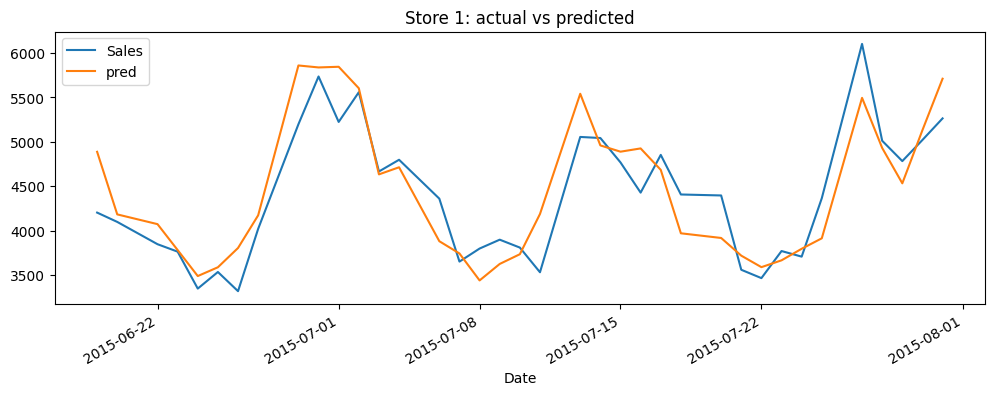

In [22]:
#predictions vs actual
valid_df = valid_df.copy()
valid_df["pred"] = lgbm.predict(X_valid)

# Total sales across all stores
daily_cmp = valid_df.groupby("Date")[["Sales", "pred"]].sum()
daily_cmp.plot(figsize=(12, 4), title="Actual vs predicted total sales (validation)")
plt.show()

# One store
s = valid_df[valid_df["Store"] == 1].set_index("Date")
s[["Sales", "pred"]].plot(figsize=(12, 4), title="Store 1: actual vs predicted")
plt.show()

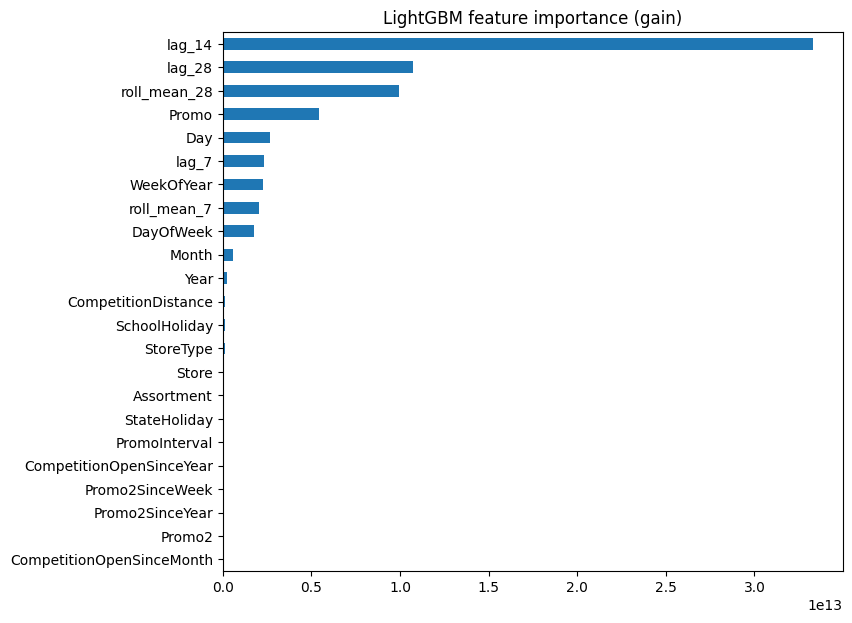

In [23]:
#gain based importance
imp_gain = pd.Series(
    lgbm.booster_.feature_importance(importance_type="gain"),
    index=features
).sort_values()
imp_gain.plot(kind="barh", figsize=(8, 7), title="LightGBM feature importance (gain)")
plt.show()


In [24]:
#log target model
lgbm_log = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42
)
lgbm_log.fit(X_train, np.log1p(y_train))
pred_log = np.expm1(lgbm_log.predict(X_valid))
evaluate("LightGBM (log target)", y_valid, pred_log)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.260790 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1985
[LightGBM] [Info] Number of data points in the train set: 767923, number of used features: 23
[LightGBM] [Info] Start training from score 8.761042
LightGBM (log target) {'MAE': 610.7, 'RMSE': np.float64(890.5), 'MAPE %': np.float64(9.19)}


In [25]:
#fairer baseline comparison
mask = (valid_df["lag_7"] > 0).values
evaluate("Last week (open days only)", y_valid[mask], valid_df.loc[mask, "lag_7"])
evaluate("LightGBM (same rows)", y_valid[mask], valid_df.loc[mask, "pred"])
evaluate("LightGBM log (same rows)", y_valid[mask], pred_log[mask])

Last week (open days only) {'MAE': 2174.7, 'RMSE': np.float64(2799.2), 'MAPE %': np.float64(31.8)}
LightGBM (same rows) {'MAE': 619.3, 'RMSE': np.float64(897.3), 'MAPE %': np.float64(9.45)}
LightGBM log (same rows) {'MAE': 608.7, 'RMSE': np.float64(881.0), 'MAPE %': np.float64(9.17)}


In [26]:
#tuning
configs = [
    {"n_estimators": 1000, "learning_rate": 0.03, "num_leaves": 63},
    {"n_estimators": 800,  "learning_rate": 0.05, "num_leaves": 127},
    {"n_estimators": 800,  "learning_rate": 0.05, "num_leaves": 31},
]

best_cfg, best_mae = None, float("inf")
for cfg in configs:
    m = lgb.LGBMRegressor(subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=42, **cfg)
    m.fit(X_train, np.log1p(y_train))
    p = np.expm1(m.predict(X_valid))
    mae = mean_absolute_error(y_valid, p)
    print(cfg, "MAE:", round(mae, 1))
    if mae < best_mae:
        best_cfg, best_mae = cfg, mae

print("Best:", best_cfg, best_mae)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.107702 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1985
[LightGBM] [Info] Number of data points in the train set: 767923, number of used features: 23
[LightGBM] [Info] Start training from score 8.761042
{'n_estimators': 1000, 'learning_rate': 0.03, 'num_leaves': 63} MAE: 621.1
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.074258 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1985
[LightGBM] [Info] Number of data points in the train set: 767923, number of used features: 23
[LightGBM] [Info] Start training from score 8.761042
{'n_estimators': 800, 'learning_rate': 0.05, 'num_leaves': 127} MAE: 603.0
[LightGBM] [Info] Auto-choosing row-

In [27]:
#time base cross validation
folds = [
    ("2015-03-20", "2015-05-01"),
    ("2015-05-01", "2015-06-12"),
    ("2015-06-12", "2015-07-31"),
]

cv_scores = []
for start, end in folds:
    tr = model_df[model_df["Date"] < start]
    va = model_df[(model_df["Date"] >= start) & (model_df["Date"] <= end)]
    m = lgb.LGBMRegressor(subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=42, **best_cfg)
    m.fit(tr[features], np.log1p(tr["Sales"]))
    p = np.expm1(m.predict(va[features]))
    mae = mean_absolute_error(va["Sales"], p)
    cv_scores.append(mae)
    print(f"{start} to {end}: MAE {mae:.1f}")

print("Mean CV MAE:", round(np.mean(cv_scores), 1))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.063114 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1985
[LightGBM] [Info] Number of data points in the train set: 686690, number of used features: 23
[LightGBM] [Info] Start training from score 8.754772
2015-03-20 to 2015-05-01: MAE 899.0
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.102737 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1985
[LightGBM] [Info] Number of data points in the train set: 724828, number of used features: 23
[LightGBM] [Info] Start training from score 8.756871
2015-05-01 to 2015-06-12: MAE 743.5
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.070382 seconds.
You can se

In [29]:
#final
import os
import joblib

final_model = lgb.LGBMRegressor(subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, random_state=42, **best_cfg)
final_model.fit(X_train, np.log1p(y_train))
final_pred = np.expm1(final_model.predict(X_valid))
evaluate("LightGBM (tuned, log target)", y_valid, final_pred)

table = pd.DataFrame(results).T.sort_values("MAE")
display(table)

# Automatically create the folder if it does not exist
output_dir = "/content/drive/MyDrive/sales-forecasting/"
os.makedirs(output_dir, exist_ok=True)

joblib.dump(final_model, os.path.join(output_dir, "lgbm_final.pkl"))
table.to_csv(os.path.join(output_dir, "results.csv"))
print(f"\nSuccessfully saved model and results to {output_dir}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.069884 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1985
[LightGBM] [Info] Number of data points in the train set: 767923, number of used features: 23
[LightGBM] [Info] Start training from score 8.761042
LightGBM (tuned, log target) {'MAE': 603.0, 'RMSE': np.float64(894.8), 'MAPE %': np.float64(9.03)}


,MAE,RMSE,MAPE %
"LightGBM (tuned, log target)",603.0,894.8,9.03
LightGBM log (same rows),608.7,881.0,9.17
LightGBM (log target),610.7,890.5,9.19
LightGBM (same rows),619.3,897.3,9.45
LightGBM,620.1,900.4,9.45
Linear Regression,824.1,1139.3,12.82
Moving avg (28d),1489.4,2106.2,20.44
Last week (open days only),2174.7,2799.2,31.80
Last week (lag_7),2178.0,2809.1,31.82



Successfully saved model and results to /content/drive/MyDrive/sales-forecasting/


In [30]:
base = df[["Store", "Date", "Promo"]]
out = base.copy()
for lag in [7, 14]:
    t = base.copy()
    t["Date"] = t["Date"] + pd.Timedelta(days=lag)
    t = t.rename(columns={"Promo": f"Promo_lag{lag}"})
    out = out.merge(t, on=["Store", "Date"], how="left")

print("Promo same as 7 days ago: ", (out["Promo"] == out["Promo_lag7"]).mean())
print("Promo same as 14 days ago:", (out["Promo"] == out["Promo_lag14"]).mean())


Promo same as 7 days ago:  0.34884178177739283
Promo same as 14 days ago: 0.8490575683070047


In [31]:
mask14 = (valid_df["lag_14"] > 0).values
evaluate("Two weeks ago (lag_14)", y_valid[mask14], valid_df.loc[mask14, "lag_14"])

Two weeks ago (lag_14) {'MAE': 813.0, 'RMSE': np.float64(1183.2), 'MAPE %': np.float64(11.77)}


In [33]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Clear any previous figures in the Matplotlib cache to prevent state corruption
plt.close('all')

IMG = "/content/drive/MyDrive/sales-forecasting/images/"
os.makedirs(IMG, exist_ok=True)

# 1. Ensure the indexes are explicitly in standard pandas datetime format
daily_cmp.index = pd.to_datetime(daily_cmp.index)
ax = daily_cmp.plot(figsize=(12, 4), title="Actual vs predicted total sales (validation)")
ax.figure.savefig(IMG + "actual_vs_pred_total.png", dpi=150, bbox_inches="tight")
plt.close(ax.figure)

# 2. Convert Store index to datetime explicitly
s.index = pd.to_datetime(s.index)
ax = s[["Sales", "pred"]].plot(figsize=(12, 4), title="Store 1: actual vs predicted")
ax.figure.savefig(IMG + "store1_actual_vs_pred.png", dpi=150, bbox_inches="tight")
plt.close(ax.figure)

# 3. Save feature importance plot
ax = imp_gain.plot(kind="barh", figsize=(8, 7), title="LightGBM feature importance (gain)")
ax.figure.savefig(IMG + "feature_importance_gain.png", dpi=150, bbox_inches="tight")
plt.close(ax.figure)

print(f"Successfully saved all plots to {IMG}")

Successfully saved all plots to /content/drive/MyDrive/sales-forecasting/images/
